In [1]:
import pandas as pd
import numpy as np
import torch

from matplotlib import pyplot
from mpl_toolkits.mplot3d import Axes3D

In [2]:
device = torch.device("cpu")

path = "dataset/creditcard.csv"
df = pd.read_csv(path)

Y_raw = df['default payment next month'].values.copy()

X_raw_delete = df.drop(columns=['ID']).values
X_raw = df.iloc[:, 1:24].values.copy()

X = torch.from_numpy(X_raw).float()
y = torch.from_numpy(Y_raw).float().unsqueeze(1) #Duda porque solamente aqui se usa unsqueeze

m = X.shape[0]

torch.manual_seed(42)
indices = torch.randperm(m)
X = X[indices]
y = y[indices]

train_size = int(0.8 * m)

X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

y_train = y_train.float()

if y_train.dim() == 1:
    y_train = y_train.unsqueeze(1)

print(f"Total de muestras (m): {m}")
print(f"X_train shape: {X_train.shape} | Dispositivo: {X_train.device}")
print(f"X_test shape:  {X_test.shape}  | Dispositivo: {X_test.device}")

print(f"Y_train shape: {y_train.shape} | Dispositivo: {y_train.device}")
print(f"Y_test shape:  {y_test.shape}  | Dispositivo: {y_test.device}")

Total de muestras (m): 30000
X_train shape: torch.Size([24000, 23]) | Dispositivo: cpu
X_test shape:  torch.Size([6000, 23])  | Dispositivo: cpu
Y_train shape: torch.Size([24000, 1]) | Dispositivo: cpu
Y_test shape:  torch.Size([6000, 1])  | Dispositivo: cpu


In [3]:
print(X_train[:,22])

tensor([    0., 10000.,     0.,  ...,     0.,  9000.,     0.])


In [4]:
print(y_train)

tensor([[1.],
        [0.],
        [0.],
        ...,
        [0.],
        [0.],
        [0.]])


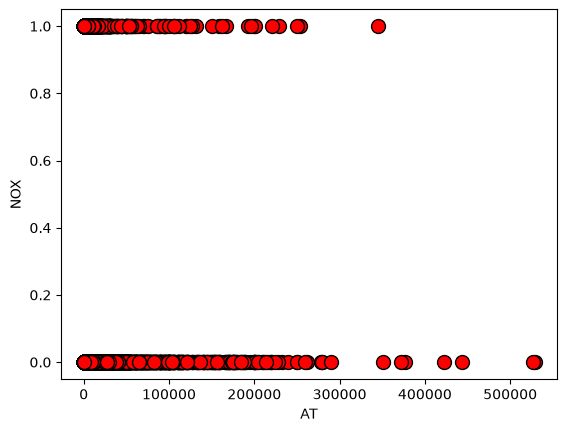

In [5]:
def plotData(x, y):

    fig = pyplot.figure()

    pyplot.plot(x, y, 'ro', ms=10, mec='k')
    pyplot.ylabel('NOX')
    pyplot.xlabel('AT')

plotData(X_train[:, 22], y_train)

In [6]:
def featureNormalize(X):
    
    mu = X_train.mean(dim=0)
    sigma = X_train.std(dim=0)

    X_norm = (X_train - mu) / sigma

    return X_norm, mu, sigma


X_train_norm, mu, sigma, = featureNormalize(X)

print(X_train_norm)

tensor([[-0.6745,  0.8126, -1.0796,  ..., -0.1621, -0.3070, -0.2914],
        [ 1.4836,  0.8126, -1.0796,  ...,  0.3342,  0.3277,  0.2667],
        [-0.6745,  0.8126,  0.1803,  ..., -0.3090, -0.3070, -0.2914],
        ...,
        [-0.8287,  0.8126, -1.0796,  ..., -0.2768, -0.2880, -0.2914],
        [ 0.5587,  0.8126,  0.1803,  ...,  0.2699,  0.8990,  0.2109],
        [ 0.0191,  0.8126,  0.1803,  ..., -0.3090, -0.3070, -0.2914]])


In [7]:
print(y_train.shape)

torch.Size([24000, 1])


In [8]:
D_in, H1, H2, D_out = 23, 128, 64, 1

# 1. Agregamos nn.Sigmoid() al final para acotar la salida a [0, 1]
model = torch.nn.Sequential(
    torch.nn.Linear(D_in, H1),
    torch.nn.ReLU(),
    torch.nn.Linear(H1, H2),
    torch.nn.ReLU(),
    torch.nn.Linear(H2, D_out),
    torch.nn.Sigmoid()
).to(device)

criterion = torch.nn.BCELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

epochs = 300
log_each = 30
loss_history = []

model.train()

for e in range(1, epochs + 1):

    # 1. Forward pass
    y_pred = model(X_train_norm)

    # 2. Loss
    loss = criterion(y_pred, y_train)
    loss_history.append(loss.item())

    # 3. Limpiar gradientes
    optimizer.zero_grad()

    # 4. Backward pass
    loss.backward()

    # 5. Actualización de pesos
    optimizer.step()

    # Imprimimos el loss puntual de la época actual
    if not e % log_each:
        print(f"Epoch {e}/{epochs} | Loss: {loss.item():.5f}")

Epoch 30/300 | Loss: 0.52173
Epoch 60/300 | Loss: 0.49283
Epoch 90/300 | Loss: 0.47807
Epoch 120/300 | Loss: 0.46851
Epoch 150/300 | Loss: 0.46193
Epoch 180/300 | Loss: 0.45728
Epoch 210/300 | Loss: 0.45391
Epoch 240/300 | Loss: 0.45136
Epoch 270/300 | Loss: 0.44934
Epoch 300/300 | Loss: 0.44771


In [9]:
model.eval()

X_test_norm = (X_test - mu) / sigma

with torch.no_grad():
    y_pred_test_prob = model(X_test_norm)
    
    # Si la probabilidad es >= 0.5 es clase 1, de lo contrario clase 0
    y_pred_clase = (y_pred_test_prob >= 0.5).float()
    
    # Porcentaje de aciertos
    exactitud = (y_pred_clase == y_test).float().mean() * 100

print(f"\nExactitud (Accuracy) en Test: {exactitud.item():.2f}%")


Exactitud (Accuracy) en Test: 80.85%


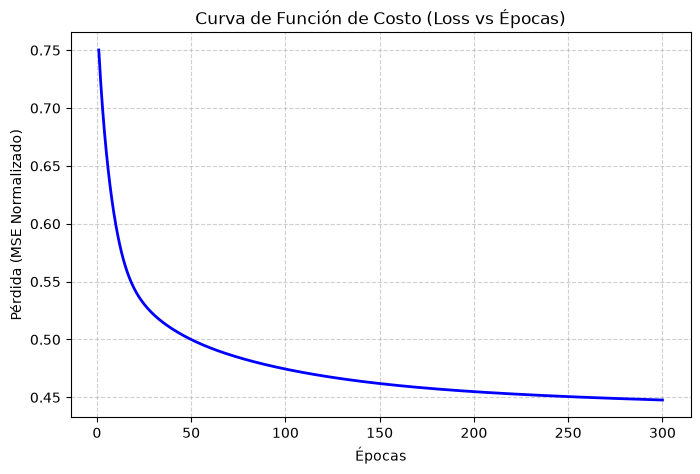

In [10]:
pyplot.figure(figsize=(8, 5))

pyplot.plot(range(1, epochs + 1), loss_history, color='blue', linewidth=2)

pyplot.title('Curva de Función de Costo (Loss vs Épocas)')
pyplot.xlabel('Épocas')
pyplot.ylabel('Pérdida (MSE Normalizado)')
pyplot.grid(True, linestyle='--', alpha=0.6)

pyplot.show()